# 02 — Modeling

Order of work:
1. Walk-forward CV on the **training** period (2006–2020) to compare models and tune.
2. Check the chosen model once on **validation** (2021–2022), including a backtest.
3. Freeze everything, then run the **test** period (2023+) once (section 7, switched off until tuning is finished).

Metrics: macro F1 and balanced accuracy (plain accuracy is misleading with imbalanced classes). ~0.35–0.40 is normal for three classes; anything far higher means a bug or a leak.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from spysignal import data, features, labels, splits
from spysignal.features import FEATURES

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 1.5,
})
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a3a29d"
CLASS_COLORS = {"Sell": "#e34948", "Hold": GRAY, "Buy": BLUE}   # diverging: red - gray - blue
NAMES = {-1: "Sell", 0: "Hold", 1: "Buy"}

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score, f1_score, confusion_matrix, make_scorer
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

from spysignal import backtest

In [2]:
# data/raw.csv is created once with data.download(); everyone uses the same file.
if not data.RAW_FILE.exists():
    data.download()
df = data.load()

X_all = features.build_features(df)
fwd = labels.forward_return(df)
scale = labels.threshold_scale(df)
usable = X_all[list(FEATURES)].notna().all(axis=1) & fwd.notna() & scale.notna()
masks = splits.split_masks(df.index, usable)

k = labels.fit_k(fwd[masks["train"]], scale[masks["train"]])   # fitted on TRAIN only
y = labels.make_labels(fwd, scale, k)
print(f"k = {k:.3f}  (Buy if 5-day return > {k:.2f} x expected 5-day volatility)")
for name, m in masks.items():
    print(f"{name:5s}: {m.sum():5d} rows  {df.index[m].min().date()} -> {df.index[m].max().date()}")

k = 0.379  (Buy if 5-day return > 0.38 x expected 5-day volatility)
train:  3636 rows  2006-07-17 -> 2020-12-22
val  :   497 rows  2021-01-04 -> 2022-12-21
test :   940 rows  2023-01-03 -> 2026-10-01


In [3]:
cols = list(FEATURES)
Xtr, ytr = X_all.loc[masks["train"], cols], y[masks["train"]].astype(int)
Xva, yva = X_all.loc[masks["val"], cols], y[masks["val"]].astype(int)

## 1. Walk-forward CV on the training period
Each model is a `Pipeline`, so the scaler is re-fit inside every fold (fitting it on all data would leak future means and variances). `TimeSeriesSplit(gap=6)` leaves a 6-day gap so a training label never overlaps the fold it is scored on. Class imbalance: `class_weight='balanced'` (sample weights for XGBoost).

In [4]:
models = {
    "dummy (majority)": DummyClassifier(strategy="most_frequent"),
    "logistic": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000)),
    "random forest": RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=50,
                                            class_weight="balanced", n_jobs=-1, random_state=0),
    "xgboost": XGBClassifier(n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.8, random_state=0),
}

def fit(model, X, y_):
    if isinstance(model, XGBClassifier):            # XGBoost needs labels 0..2 and sample weights
        return model.fit(X, y_ + 1, sample_weight=compute_sample_weight("balanced", y_))
    return model.fit(X, y_)

def predict(model, X):
    p = model.predict(X)
    return pd.Series(p - 1 if isinstance(model, XGBClassifier) else p, index=X.index)

def cv_score(model, X=Xtr, y_=ytr):
    """Walk-forward CV on the training period. Returns one row per fold."""
    rows = []
    for fold, (tr, te) in enumerate(splits.cv_splitter().split(X)):
        fit(model, X.iloc[tr], y_.iloc[tr])
        pred = predict(model, X.iloc[te])
        rows.append({"fold": fold, "macro_f1": f1_score(y_.iloc[te], pred, average="macro"),
                     "balanced_acc": balanced_accuracy_score(y_.iloc[te], pred)})
    return pd.DataFrame(rows)

cv = pd.concat({name: cv_score(m) for name, m in models.items()}, names=["model"]).reset_index(level=0)
cv_table = cv.groupby("model")[["macro_f1", "balanced_acc"]].agg(["mean", "std"]).round(3)
display(cv_table)

macro_f1        balanced_acc       
                     mean    std         mean    std
model                                               
dummy (majority)    0.199  0.007        0.333  0.000
logistic            0.367  0.021        0.386  0.026
random forest       0.372  0.022        0.393  0.022
xgboost             0.360  0.038        0.383  0.016

## 2. Sanity check: shuffled labels
Train on randomly shuffled labels. Scores must drop to chance (~0.33). If they don't, something in the pipeline is leaking.

In [5]:
rng = np.random.default_rng(0)
shuffled = pd.Series(rng.permutation(ytr.to_numpy()), index=ytr.index)
print(f"balanced accuracy on shuffled labels: {cv_score(models['logistic'], y_=shuffled)['balanced_acc'].mean():.3f}")

balanced accuracy on shuffled labels: 0.321


## 3. Hyperparameter tuning
**TODO (group).** Use `cv_score` on the training period only, e.g.:

```python
for depth in [2, 3, 4, 6]:
    m = RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=50,
                               class_weight='balanced', n_jobs=-1, random_state=0)
    print(depth, cv_score(m)['macro_f1'].mean().round(3))
```

Keep grids small: every extra setting tried is another chance to fit noise. Update the `models` dict with the winners, then re-run the notebook.

## 4. Model choice
The model with the best mean CV macro F1 on the training period. Validation and test play no part in this choice.

In [6]:
best = cv_table[("macro_f1", "mean")].drop("dummy (majority)").idxmax()
final = models[best]
print("chosen model:", best)

chosen model: random forest


## 5. Validation check (2021–2022)
Fit on the full training period, predict validation once.

We also split the 3-class problem into the two questions it contains:
- **Hold vs move:** will the next week be quiet or not?
- **Buy vs Sell:** on weeks that really moved and where the model called a move, did it get the direction right?

--- Dummy, validation ---
macro F1 0.189 | balanced accuracy 0.333 | plain accuracy 0.394
Hold vs move, balanced accuracy: 0.500  (chance 0.50)
Buy vs Sell when both are moves: 0.552 on 355 days (always guessing Buy would score 0.552)
predicted class mix: {'Buy': 1.0}


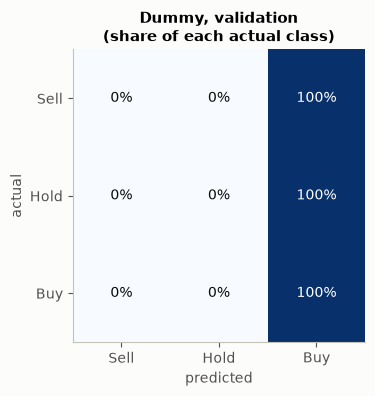

--- random forest, validation ---
macro F1 0.406 | balanced accuracy 0.420 | plain accuracy 0.408
Hold vs move, balanced accuracy: 0.606  (chance 0.50)
Buy vs Sell when both are moves: 0.538 on 223 days (always guessing Buy would score 0.565)
predicted class mix: {'Hold': 0.43, 'Sell': 0.3, 'Buy': 0.27}


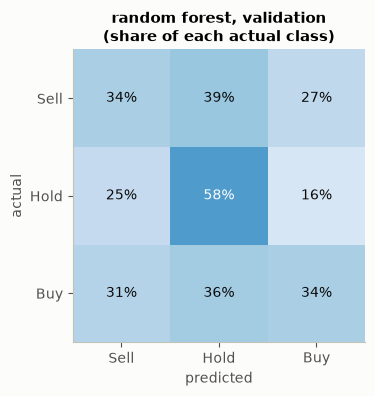

In [7]:
def evaluate(pred, y_true, title):
    print(f"--- {title} ---")
    print(f"macro F1 {f1_score(y_true, pred, average='macro'):.3f} | "
          f"balanced accuracy {balanced_accuracy_score(y_true, pred):.3f} | "
          f"plain accuracy {(pred == y_true).mean():.3f}")
    move_true, move_pred = y_true != 0, pred != 0
    print(f"Hold vs move, balanced accuracy: {balanced_accuracy_score(move_true, move_pred):.3f}  (chance 0.50)")
    both = move_true & move_pred
    print(f"Buy vs Sell when both are moves: {(pred[both] == y_true[both]).mean():.3f} on {both.sum()} days "
          f"(always guessing Buy would score {(y_true[both] == 1).mean():.3f})")
    print("predicted class mix:", pred.map(NAMES).value_counts(normalize=True).round(2).to_dict())

    cm = confusion_matrix(y_true, pred, labels=[-1, 0, 1], normalize="true")
    fig, ax = plt.subplots(figsize=(4.2, 3.8))
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "#0b0b0b")
    ticks = ["Sell", "Hold", "Buy"]
    ax.set_xticks(range(3), ticks); ax.set_yticks(range(3), ticks); ax.grid(False)
    ax.set_xlabel("predicted"); ax.set_ylabel("actual")
    ax.set_title(f"{title}\n(share of each actual class)")
    plt.show()

fit(final, Xtr, ytr)
pred_va = predict(final, Xva)
evaluate(predict(fit(models["dummy (majority)"], Xtr, ytr), Xva), yva, "Dummy, validation")
evaluate(pred_va, yva, f"{best}, validation")

### Which features does the model rely on?
Permutation importance on validation: shuffle one feature at a time and measure how much macro F1 drops. Near zero (or negative) means the model gains nothing from that feature out of sample.

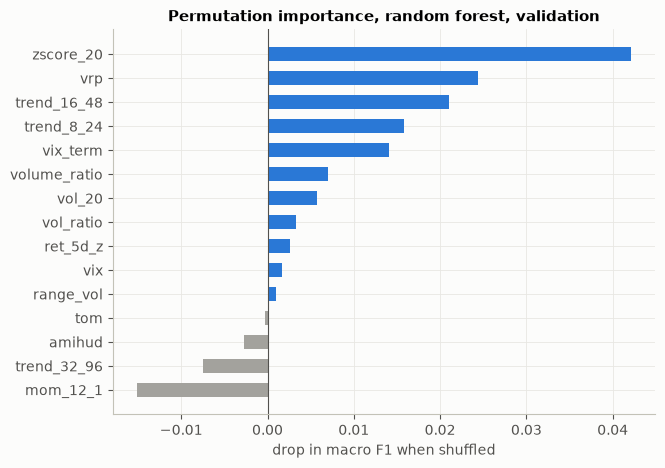

In [8]:
fit(final, Xtr, ytr)
y_for_score = yva + 1 if isinstance(final, XGBClassifier) else yva
imp = permutation_importance(final, Xva, y_for_score, scoring=make_scorer(f1_score, average="macro"),
                             n_repeats=20, random_state=0)
imp = pd.Series(imp.importances_mean, index=cols).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp, color=[BLUE if v > 0 else GRAY for v in imp], height=0.6)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_xlabel("drop in macro F1 when shuffled")
ax.set_title(f"Permutation importance, {best}, validation")
plt.show()

## 6. Backtest on validation (2021–2022)
Long/cash: Buy → invest, Sell → cash, Hold → keep position. Signal at close t, trade at open t+1, 0.1% per trade. Compared with:
- **Buy & Hold SPY** (the assignment's benchmark);
- the **same model with no fees**, to see how much the fees cost;
- **random signals**: the model's own predictions shuffled in time (same number of Buy/Sell/Hold days), 200 times. If the model doesn't beat its shuffled self, its timing adds nothing.

model beats 99% of random-timing runs on total return


,model,"model, no fees",Buy & Hold,random (median)
total_return,20.1%,27.5%,5.2%,-11.2%
cagr,9.7%,13.1%,2.6%,-5.8%
ann_vol,11.6%,11.6%,19.2%,13.1%
sharpe,0.86,1.12,0.23,-0.41
max_drawdown,-10.3%,-8.7%,-26.3%,-23.0%
orders,60,60,1,140
fees_paid,$656,$0,$10,"$1,390"
time_in_market,37.4%,37.4%,100.0%,46.5%


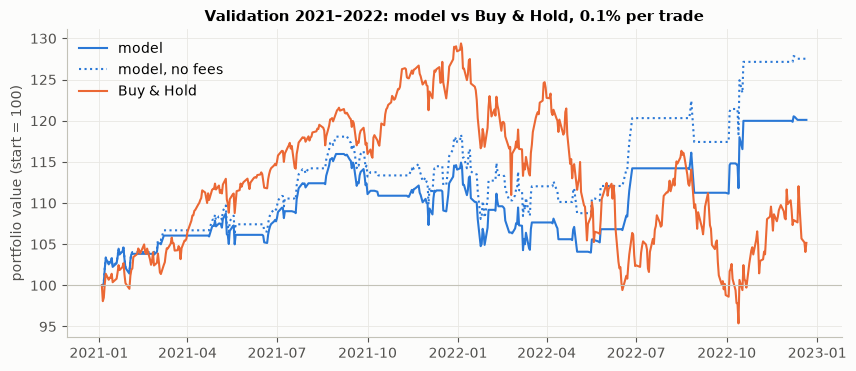

In [9]:
def backtest_report(pred, title, n_random=200):
    open_px = df["open"].loc[pred.index[0]:pred.index[-1]]
    pfs = {"model": backtest.run(pred, open_px),
           "model, no fees": backtest.run(pred, open_px, fee=0.0),
           "Buy & Hold": backtest.buy_and_hold(open_px)}
    table = pd.DataFrame({k: backtest.summary(v) for k, v in pfs.items()})

    rng = np.random.default_rng(0)
    rand = pd.DataFrame([backtest.summary(backtest.run(
        pd.Series(rng.permutation(pred.to_numpy()), index=pred.index), open_px)) for _ in range(n_random)])
    table["random (median)"] = rand.median()
    model_ret = table.loc["total_return", "model"]
    print(f"model beats {(rand['total_return'] < model_ret).mean():.0%} of random-timing runs on total return")

    fmt = {r: "{:.1%}" for r in ["total_return", "cagr", "ann_vol", "max_drawdown", "time_in_market"]}
    fmt.update(sharpe="{:.2f}", orders="{:.0f}", fees_paid="${:,.0f}")
    display(table.apply(lambda row: row.map(lambda v: fmt.get(row.name, "{:.3f}").format(v)), axis=1))

    fig, ax = plt.subplots(figsize=(10, 4))
    styles = {"model": (BLUE, "-"), "model, no fees": (BLUE, ":"), "Buy & Hold": (ORANGE, "-")}
    for name, pf in pfs.items():
        v = pf.value()
        color, ls = styles[name]
        ax.plot(v.index, v / v.iloc[0] * 100, color=color, linestyle=ls, label=name)
    ax.axhline(100, color="#c3c2b7", linewidth=0.8)
    ax.set_ylabel("portfolio value (start = 100)")
    ax.set_title(f"{title}: model vs Buy & Hold, 0.1% per trade")
    ax.legend(frameon=False, loc="upper left")
    plt.show()
    return table

val_table = backtest_report(pred_va, "Validation 2021–2022")

### Is validation a fluke? Backtest every training CV fold
Validation is only two years, and one of them (2022) was a bear market. The CV folds give five more out-of-sample periods from the training era, each predicted by a model trained only on earlier data.

In [10]:
fold_rows = []
for tr, te in splits.cv_splitter().split(Xtr):
    fit(final, Xtr.iloc[tr], ytr.iloc[tr])
    p = predict(final, Xtr.iloc[te])
    o = df["open"].loc[p.index[0]:p.index[-1]]
    a, b = backtest.summary(backtest.run(p, o)), backtest.summary(backtest.buy_and_hold(o))
    fold_rows.append({"period": f"{p.index[0]:%Y-%m} to {p.index[-1]:%Y-%m}",
                      "model return": a.total_return, "B&H return": b.total_return,
                      "model Sharpe": a.sharpe, "B&H Sharpe": b.sharpe,
                      "model drawdown": a.max_drawdown, "B&H drawdown": b.max_drawdown,
                      "time in market": a.time_in_market})
folds_bt = pd.DataFrame(fold_rows).set_index("period")
display(folds_bt.style.format({c: "{:.2f}" if "Sharpe" in c else "{:.1%}" for c in folds_bt.columns}))

# What drives the position? Correlate exposure with volatility and trend (validation period).
pos = backtest.signals_to_position(pred_va)
print("corr(position, vol_20):    ", round(pos.corr(Xva["vol_20"]), 2))
print("corr(position, trend_32_96):", round(pos.corr(Xva["trend_32_96"]), 2))
for yr in [2021, 2022]:
    print(f"{yr}: in the market {pos[pos.index.year == yr].mean():.0%} of days")

,model return,B&H return,model Sharpe,B&H Sharpe,model drawdown,B&H drawdown,time in market
period,,,,,,,
2008-12 to 2011-05,9.4%,57.8%,0.60,1.01,-5.2%,-27.4%,28.5%
2011-05 to 2013-10,16.2%,32.6%,0.66,0.78,-10.4%,-19.4%,70.3%
2013-10 to 2016-03,15.4%,23.3%,0.60,0.68,-10.8%,-13.3%,77.1%
2016-03 to 2018-07,7.5%,49.9%,0.39,1.65,-10.4%,-9.8%,39.8%
2018-07 to 2020-12,16.9%,37.2%,0.53,0.71,-14.8%,-32.0%,59.9%


corr(position, vol_20):     -0.31
corr(position, trend_32_96): 0.29
2021: in the market 48% of days
2022: in the market 27% of days


## 7. Final test (2023 onward): run once
**Switched off until tuning is finished.** When the group has frozen the features, the model and its settings, set `RUN_FINAL_TEST = True`, run the notebook once, and do not change anything afterwards. The model is refit on training + validation; k stays as fitted on training.

In [11]:
RUN_FINAL_TEST = False

if RUN_FINAL_TEST:
    dev = masks["train"] | masks["val"]
    Xte, yte = X_all.loc[masks["test"], cols], y[masks["test"]].astype(int)
    fit(final, X_all.loc[dev, cols], y[dev].astype(int))
    pred_te = predict(final, Xte)
    evaluate(pred_te, yte, f"{best}, TEST")
    test_table = backtest_report(pred_te, "Test 2023+")
else:
    print("Final test is locked. Set RUN_FINAL_TEST = True only once, after tuning is frozen.")

Final test is locked. Set RUN_FINAL_TEST = True only once, after tuning is frozen.


## 8. Lessons learned

*Draft written from the untuned run (random forest, before section 3 tuning, before the final test). Re-check every number after tuning, and add the test results.*

**1. The model has some skill, and it is real, not leakage.** Cross-validated macro F1 is about 0.37 against 0.20 for the Dummy, and 0.41 on validation. That is in the 0.35–0.40 range the assignment says to expect. Training on shuffled labels drops the score to chance (0.32), and the leakage tests check feature timing, label windows, split gaps and trade timing.

**2. The skill is about *how much* the market moves, not *which way*.** Splitting the problem in two:
- *Hold vs move:* 0.61 balanced accuracy (chance is 0.50). Volatility clusters. Our label threshold uses 60-day volatility, which reacts slowly, so when short-term volatility is rising (`vol_ratio`, VIX term structure) the next week tends to exceed the threshold.
- *Buy vs Sell:* when the week really moved, the model got the direction right 54% of the time. Always guessing Buy would have scored 56.5%. **No directional skill.** This is the efficient-markets result in miniature: volatility is forecastable, direction mostly isn't.

**3. The validation backtest looks great, but that is the 2022 bear market.** On 2021–22 the model returned +20% against +5% for Buy & Hold, with half the volatility and a −10% max drawdown against −26%. But:
- In 2022 the model was in the market only about 27% of days. Its position is negatively correlated with volatility and positively correlated with trend, so it acts as a **risk-off filter**, not a direction forecaster.
- In **all five** training-period CV folds (2008–2020, mostly bull markets) the same model **lost to Buy & Hold** on both total return and Sharpe.
- A filter like this pays off in crashes and costs money in rallies. The test period (2023 onward) has been mostly a strong bull market, so expect the model to lag Buy & Hold there.

**4. Fees matter even with "Hold = keep position".** 60 trades in two years cost about 6.5% of starting capital, cutting the return from +27.5% to +20%. With the same mix of signals placed at random times, the model trades 140 times and pays about 14%. A model that flips daily would lose to fees almost regardless of its accuracy.

**5. What the model relies on** (permutation importance on validation): the 20-day z-score (mean reversion), the variance risk premium (VIX minus realized volatility) and the fast/medium trend signals. The slow momentum features (`mom_12_1`, `trend_32_96`) *hurt* out of sample. The VWAP proxy was dropped in EDA because it duplicates the moving-average ratio (correlation 0.99).

**6. Why predicting SPY is hard:**
- *Few independent observations.* Overlapping 5-day labels mean 2 years of validation contain only about 100 non-overlapping weeks. Most of the result can come from one regime, as 2022 shows.
- *Regime dependence.* What helped in 2008 and 2022 (being in cash) hurts in 2013–2021-style rallies.
- *Low signal-to-noise.* Single features have |rank correlation| below 0.08 with next week's return.
- *Every extra setting tried is another chance to fit noise*, which is why tuning stays small and the test set is used once.

**7. Simplifying assumptions in the backtest:**
- Cash earns 0%. T-bills paid about 4–5% in 2023–25, so this *understates* a strategy that sits in cash.
- 0.1% per trade is conservative for SPY, whose spread is about 0.3 basis points.
- No taxes and no short selling (long/cash only).
- k (the label threshold) is fitted on training data only.
